# CIFAR-10 图像分类（Jupyter 版）

- 训练：CNN 分类 10 类 CIFAR-10 图片
- 运行前请把 Jupyter 内核切换到 `D:\LiMu\.venv-dml`（Python 3.10，已装 torch / torchvision / torch-directml / matplotlib）
- 训练在 CPU 上进行（DirectML 反向传播支持不完善，仅用于后面的推理可视化）


In [1]:
import os
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import csv
log = open('train_log.csv', 'w', newline='', encoding='utf-8')
writer = csv.writer(log)
writer.writerow(['epoch', 'train_loss', 'test_acc', 'lr'])
%matplotlib inline
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False


In [2]:
DATA_ROOT = r"D:\156245545\练手数据集"
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
batch_size = 128
epochs = 20


In [3]:
class BetterCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.20),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.30),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        # 32×32 经 3 次池化 → 4×4，展平维度 = 128*4*4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.40),
            nn.Linear(128 * 4 * 4, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [4]:
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_ROOT, train=True, download=True, transform=train_transform,
)
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_ROOT, train=False, download=True, transform=test_transform,
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("使用设备:", device)

model = BetterCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)


使用设备: cpu


In [7]:
for epoch in range(epochs):
    # 训练
    model.train()
    running_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    scheduler.step()

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            _, pred = torch.max(outputs, dim=1)
            total += labels.size(0)
            correct += (pred == labels).sum().item()

    print(f"Epoch[{epoch + 1}/{epochs}] "
          f"Loss:{running_loss / len(train_loader):.4f} "
          f"Acc:{correct / total:.4f}")
    writer.writerow([epoch + 1,
                 round(running_loss / len(train_loader), 4),
                 round(correct / total, 4),
                 optimizer.param_groups[0]['lr']])
    log.flush()
    # 测试


Epoch[1/20] Loss:1.4297 Acc:0.5809
Epoch[2/20] Loss:1.2307 Acc:0.6257
Epoch[3/20] Loss:1.1015 Acc:0.6461
Epoch[4/20] Loss:1.0071 Acc:0.7208
Epoch[5/20] Loss:0.9081 Acc:0.7194
Epoch[6/20] Loss:0.8759 Acc:0.7468
Epoch[7/20] Loss:0.8489 Acc:0.7553
Epoch[8/20] Loss:0.8250 Acc:0.7654
Epoch[9/20] Loss:0.7959 Acc:0.7680
Epoch[10/20] Loss:0.7606 Acc:0.7756
Epoch[11/20] Loss:0.7482 Acc:0.7770
Epoch[12/20] Loss:0.7356 Acc:0.7800
Epoch[13/20] Loss:0.7253 Acc:0.7888
Epoch[14/20] Loss:0.7152 Acc:0.7921
Epoch[15/20] Loss:0.6957 Acc:0.7985
Epoch[16/20] Loss:0.6858 Acc:0.7964
Epoch[17/20] Loss:0.6841 Acc:0.8029
Epoch[18/20] Loss:0.6751 Acc:0.7993
Epoch[19/20] Loss:0.6744 Acc:0.8055
Epoch[20/20] Loss:0.6647 Acc:0.8042


In [8]:
# 保存模型权重，供后面的预测可视化加载
weights_path = os.path.join(os.getcwd(), "cifar10_cnn.pth")
torch.save(model.state_dict(), weights_path)
print("模型权重已保存:", weights_path)


模型权重已保存: C:\Users\1\Doubao\chats\2026-11-14\new-chat\cifar10_cnn.pth


## 图片可视化

下面两格分别展示数据集原图，以及训练后模型在测试集上的预测对比（绿色=正确，红色=错误）。


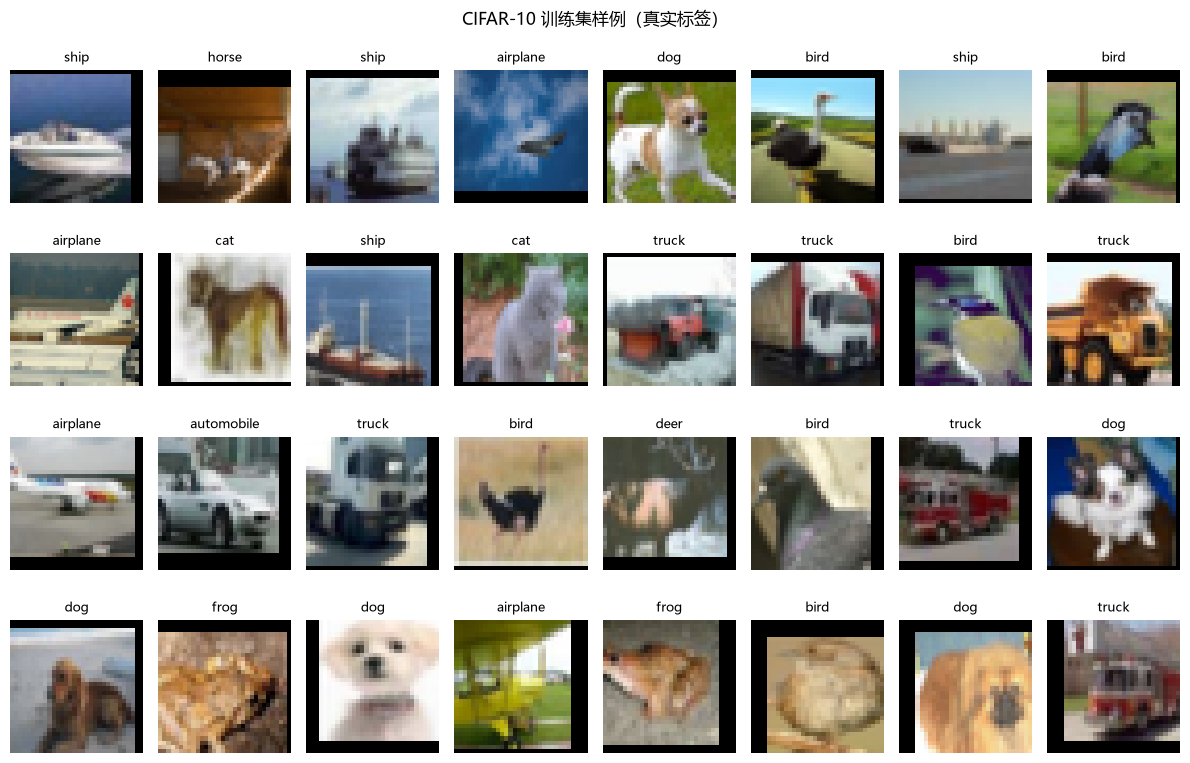

In [9]:
def denormalize(tensor):
    """Normalize 的逆操作，还原到 [0,1] 显示范围。"""
    mean_t = torch.tensor(mean).view(3, 1, 1)
    std_t = torch.tensor(std).view(3, 1, 1)
    return (tensor * std_t + mean_t).clamp(0, 1)


images, labels = next(iter(DataLoader(train_dataset, batch_size=32, shuffle=True)))
images = denormalize(images)

ncols = 8
nrows = int(np.ceil(32 / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2 * nrows))
axes = axes.flatten()
for i in range(32):
    axes[i].imshow(images[i].permute(1, 2, 0).numpy())
    axes[i].set_title(CLASSES[labels[i]], fontsize=9)
    axes[i].axis("off")
fig.suptitle("CIFAR-10 训练集样例（真实标签）")
plt.tight_layout()
plt.show()


推理设备: cpu


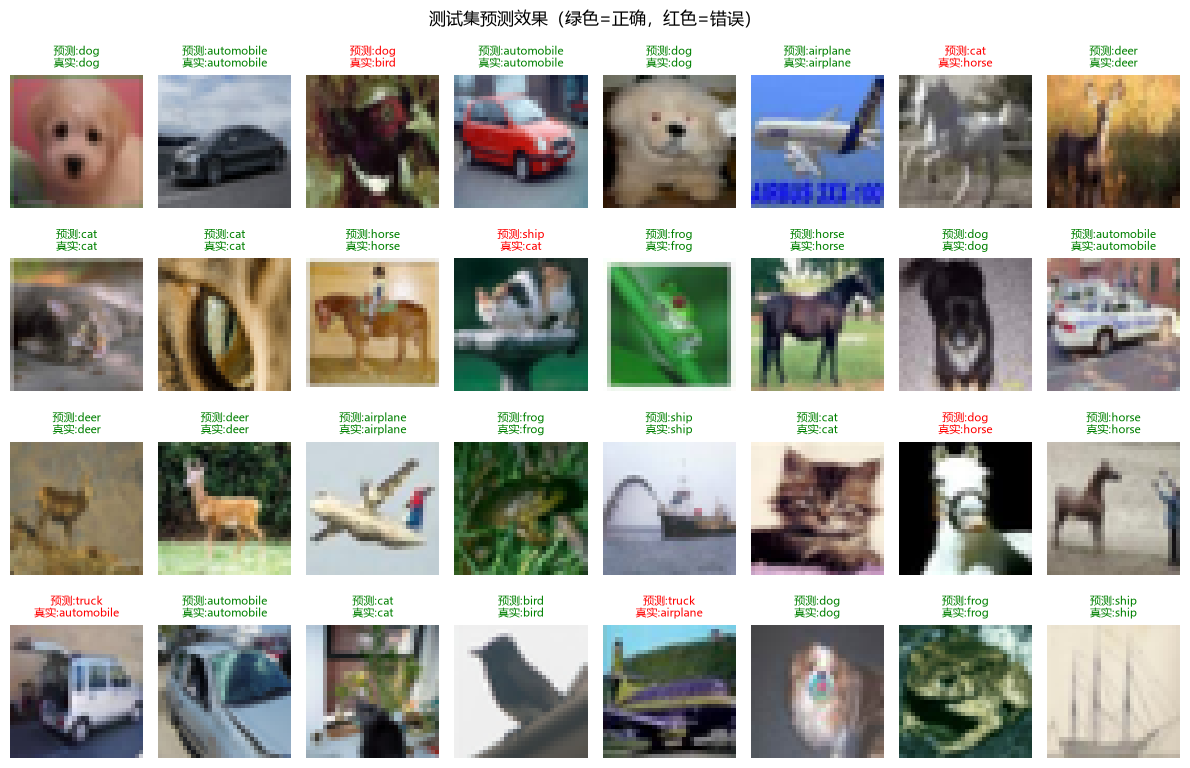

In [10]:
# 推理设备：优先 DirectML（6650 XT），不可用则 CPU
try:
    import torch_directml
    infer_device = torch_directml.device() if torch_directml.is_available() else torch.device("cpu")
except ImportError:
    infer_device = torch.device("cpu")
print("推理设备:", infer_device)

infer_model = BetterCNN().to(infer_device)
state_dict = torch.load(weights_path, map_location="cpu", weights_only=True)
infer_model.load_state_dict(state_dict)
infer_model.eval()

images, labels = next(iter(DataLoader(test_dataset, batch_size=32, shuffle=True)))
images_dev = images.to(infer_device)
with torch.no_grad():
    _, preds = infer_model(images_dev).max(1)
preds = preds.cpu()
images = denormalize(images)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2 * nrows))
axes = axes.flatten()
for i in range(32):
    axes[i].imshow(images[i].permute(1, 2, 0).numpy())
    ok = preds[i] == labels[i]
    axes[i].set_title(f"预测:{CLASSES[preds[i]]}\n真实:{CLASSES[labels[i]]}",
                      fontsize=8, color="green" if ok else "red")
    axes[i].axis("off")
fig.suptitle("测试集预测效果（绿色=正确，红色=错误）")
plt.tight_layout()
plt.show()
